In [1]:
import sys, warnings, time
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
import tensorflow as tf
from tensorflow import keras  # type: ignore
from arch import arch_model
from arch.bootstrap import MCS

TICKERS = ["^GSPC"]                       # add e.g. "AAPL", "JPM" if you like (about 5 min per asset)
START = "2010-01-01"
N_SEEDS = 3                               # 5 for a final run
LOOK = 22
FOLD_STARTS = [0.5, 0.6, 0.7, 0.8, 0.9]   # training ends at these fractions of the data
FOLD_LEN = 0.1                            # each test block = next 10% of the data

In [2]:
def load_returns(ticker):
    px = yf.download(ticker, start=START, auto_adjust=True, progress=False)
    if isinstance(px.columns, pd.MultiIndex):
        px.columns = px.columns.get_level_values(0)
    close = px["Close"].dropna()
    r = (100 * np.log(close / close.shift(1))).dropna()
    r.name = "log_return"
    return r

SPECS = {
    "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
    "EGARCH":     dict(vol="EGARCH", p=1, o=1, q=1),
    "GJR-GARCH":  dict(vol="GARCH", p=1, o=1, q=1),
}

def garch_forecasts(r, split, end):
    """Estimate on r[:split] only; one-day-ahead forecasts for the test block r[split:end]."""
    gf_all, test = {}, {}
    for name, spec in SPECS.items():
        res = arch_model(r, mean="Constant", dist="t", **spec).fit(last_obs=r.index[split - 1], disp="off")
        gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]  # made at t, for t+1
        gf_all[name] = gf
        test[name] = gf.shift(1).loc[r.index[split:end]]
    test["Rolling 21d var"] = r.rolling(21).var().shift(1).loc[r.index[split:end]]
    return gf_all, pd.DataFrame(test)

In [3]:
def qlike_loss(y_true, y_pred):
    y_, base = y_true[:, 0:1], y_true[:, 1:2]
    out = tf.clip_by_value(y_pred, -4.0, 4.0)
    f = base * tf.exp(out)
    return tf.reduce_mean(tf.math.log(f) + y_ / f)

def build_model(n_feat, lr=3e-4):
    m = keras.Sequential([
        keras.layers.Input(shape=(LOOK, n_feat)),
        keras.layers.LSTM(16),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=qlike_loss)
    return m

def train_ensemble(s, n_seeds):
    preds = []
    for seed in range(n_seeds):
        np.random.seed(seed); tf.random.set_seed(seed)
        m = build_model(s["X_tr"].shape[2])
        early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
        m.fit(s["X_tr"], s["Y_tr"], validation_data=(s["X_val"], s["Y_val"]),
              epochs=200, batch_size=64, callbacks=[early], verbose=0)
        out = np.clip(m.predict(s["X_te"], verbose=0).ravel(), -4, 4)
        preds.append(s["Y_te"][:, 1] * np.exp(out))
    return np.array(preds).mean(axis=0)

def nn_forecasts(r, gjr_gf, split, end, n_seeds):
    feat = pd.DataFrame({
        "ret": r, "sq_ret": r ** 2,
        "abs_mean_5d": r.abs().rolling(5).mean(),
        "rv_21d": r.rolling(21).std() * np.sqrt(252),
        "log_garch_var": np.log(gjr_gf),
    }).dropna()
    split_date = r.index[split]
    end_date = r.index[end] if end < len(r) else r.index[-1] + pd.Timedelta(days=1)

    tr = feat.index < split_date                       # scaling uses training data only
    mu, sd = feat[tr].mean(), feat[tr].std()
    feat_s = ((feat - mu) / sd).clip(-5, 5)
    vals, idx = feat_s.values, feat_s.index
    rsq = (r ** 2).loc[idx].values
    gv = gjr_gf.loc[idx].values

    X, y, g, dates = [], [], [], []
    for t in range(LOOK, len(idx)):
        X.append(vals[t - LOOK:t]); y.append(rsq[t]); g.append(gv[t - 1]); dates.append(idx[t])
    X, y, g, dates = np.array(X), np.array(y), np.array(g), pd.DatetimeIndex(dates)

    train_mask = dates < split_date
    test_mask = (dates >= split_date) & (dates < end_date)
    const_var = (r ** 2)[r.index < split_date].mean()

    def make_sets(X_, base):
        Y = np.column_stack([y, base])
        Xa, Ya = X_[train_mask], Y[train_mask]
        v = int(len(Xa) * 0.9)
        return dict(X_tr=Xa[:v], Y_tr=Ya[:v], X_val=Xa[v:], Y_val=Ya[v:],
                    X_te=X_[test_mask], Y_te=Y[test_mask])

    out = pd.DataFrame(index=dates[test_mask])
    out["Hybrid"] = train_ensemble(make_sets(X, g), n_seeds)
    out["LSTM"] = train_ensemble(make_sets(X[:, :, :4], np.full(len(y), const_var)), n_seeds)
    return out

In [4]:
def run_fold(r, split_frac):
    n = len(r)
    split = int(n * split_frac)
    end = min(int(n * (split_frac + FOLD_LEN)), n)
    gf_all, fc = garch_forecasts(r, split, end)
    nn = nn_forecasts(r, gf_all["GJR-GARCH"], split, end, N_SEEDS)
    return fc.join(nn, how="inner").dropna().clip(lower=1e-8)

folds = {}
for tk in TICKERS:
    r = load_returns(tk)
    folds[tk] = []
    for f in FOLD_STARTS:
        t0 = time.time()
        fc = run_fold(r, f)
        folds[tk].append(fc)
        print(f"{tk} fold {f:.1f}: test {fc.index[0].date()} to {fc.index[-1].date()} "
              f"({len(fc)} days), {time.time() - t0:.0f}s")

^GSPC fold 0.5: test 2018-05-24 to 2020-01-28 (422 days), 82s
^GSPC fold 0.6: test 2020-01-29 to 2021-09-29 (422 days), 104s
^GSPC fold 0.7: test 2021-09-30 to 2023-06-05 (422 days), 64s
^GSPC fold 0.8: test 2023-06-06 to 2025-02-10 (422 days), 72s
^GSPC fold 0.9: test 2025-02-11 to 2026-10-16 (423 days), 118s


In [5]:
def fold_table(tk):
    r = load_returns(tk)
    rows = {}
    for fc in folds[tk]:
        proxy = r.loc[fc.index] ** 2
        q = fc.apply(lambda f: (np.log(f) + proxy / f).mean())
        rows[f"{fc.index[0].date()} to {fc.index[-1].date()}"] = q
    return pd.DataFrame(rows).T

tables = {tk: fold_table(tk) for tk in TICKERS}
for tk, tab in tables.items():
    print(tk, "- QLIKE by test block (lower is better)")
    display(tab.round(4))
    rel = tab.sub(tab["GJR-GARCH"], axis=0)
    print(f"Hybrid beats GJR-GARCH in {(rel['Hybrid'] < 0).sum()} of {len(rel)} blocks; "
          f"LSTM in {(rel['LSTM'] < 0).sum()}; EGARCH in {(rel['EGARCH'] < 0).sum()}; "
          f"GARCH(1,1) in {(rel['GARCH(1,1)'] < 0).sum()}\n")

^GSPC - QLIKE by test block (lower is better)


,"GARCH(1,1)",EGARCH,GJR-GARCH,Rolling 21d var,Hybrid,LSTM
2018-05-24 to 2020-01-28,0.4809,0.3771,0.4099,0.6958,0.4046,0.3822
2020-01-29 to 2021-09-29,1.2832,1.6762,1.4441,1.4645,1.4750,1.7440
2021-09-30 to 2023-06-05,1.4915,1.4474,1.4819,1.5144,1.4668,1.4265
2023-06-06 to 2025-02-10,0.5071,0.4777,0.4709,0.6093,0.4506,0.4272
2025-02-11 to 2026-10-16,0.7696,0.6946,0.6896,0.8856,0.6704,0.6552


Hybrid beats GJR-GARCH in 4 of 5 blocks; LSTM in 4; EGARCH in 2; GARCH(1,1) in 1



In [6]:
def dm_test(proxy, fa, fb, lags=5):
    fa, fb = fa.clip(lower=1e-8), fb.clip(lower=1e-8)
    d = ((np.log(fa) + proxy / fa) - (np.log(fb) + proxy / fb)).values
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.tvalues[0], res.pvalues[0]

for tk in TICKERS:
    r = load_returns(tk)
    pooled = pd.concat(folds[tk])
    proxy = r.loc[pooled.index] ** 2
    losses = pooled.apply(lambda f: np.log(f) + proxy / f)
    print(f"===== {tk}: pooled over {len(pooled)} test days =====")
    print("Pooled QLIKE:")
    display(losses.mean().sort_values().round(4).to_frame("QLIKE"))
    print("Diebold-Mariano vs GJR-GARCH (negative = model has lower loss):")
    for m in ["GARCH(1,1)", "EGARCH", "LSTM", "Hybrid", "Rolling 21d var"]:
        s_, p_ = dm_test(proxy, pooled[m], pooled["GJR-GARCH"])
        print(f"  {m:16s} DM = {s_:6.2f}   p = {p_:.3f}")
    mcs = MCS(losses, size=0.10, reps=1000, seed=42)
    mcs.compute()
    print("90% Model Confidence Set:", list(mcs.included), "\n")

===== ^GSPC: pooled over 2111 test days =====
Pooled QLIKE:


,QLIKE
Hybrid,0.8934
GJR-GARCH,0.8992
"GARCH(1,1)",0.9064
LSTM,0.9269
EGARCH,0.9345
Rolling 21d var,1.0338


Diebold-Mariano vs GJR-GARCH (negative = model has lower loss):
  GARCH(1,1)       DM =   0.22   p = 0.827
  EGARCH           DM =   0.87   p = 0.383
  LSTM             DM =   0.63   p = 0.529
  Hybrid           DM =  -0.49   p = 0.624
  Rolling 21d var  DM =   3.02   p = 0.003
90% Model Confidence Set: ['EGARCH', 'GARCH(1,1)', 'GJR-GARCH', 'Hybrid', 'LSTM'] 



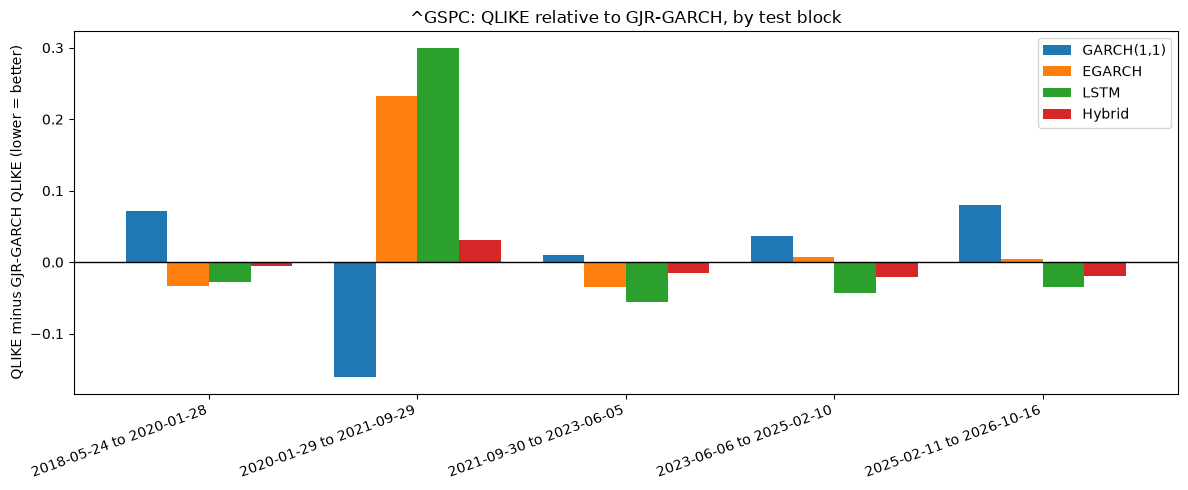

In [7]:
for tk, tab in tables.items():
    rel = tab[["GARCH(1,1)", "EGARCH", "LSTM", "Hybrid"]].sub(tab["GJR-GARCH"], axis=0)
    ax = rel.plot(kind="bar", figsize=(12, 5), width=0.8)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel("QLIKE minus GJR-GARCH QLIKE (lower = better)")
    ax.set_title(f"{tk}: QLIKE relative to GJR-GARCH, by test block")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()